# Data Mining Project

#### REGRESSION: Univariate and Multivariate Regression
* Choosing 2 or more continuous variables and using different regressors:
* linear, ridge, lasso, Decision Tree, KNN


### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Ottimizzazione dei caratteri (solo se vuoi)
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_regression/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_regression/ already exists.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
df_train

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15604,Caprices,1942,\N,58,0,73,4,0,45,1,...,-0.33267,0.127457,0.256875,-0.277418,0.236295,0.295718,0.264517,-0.316269,2.187287,0.819669
15605,Haar Jeet,1990,\N,58,0,15,2,0,22,0,...,-0.33267,-0.742626,-0.170960,-0.277418,0.236295,-0.327654,-0.517037,-0.316269,-0.661879,-0.015936
15606,Kotigobba 3,2021,\N,140,0,2560,39,3,129,0,...,-0.33267,2.140973,1.998481,3.823313,1.384864,1.230032,-0.517037,3.308314,0.891610,2.919497
15607,Ator l'invincibile,1982,\N,58,0,3011,52,1,53,55,...,-0.33267,2.233128,2.234174,1.772947,0.236295,0.439920,4.021721,-0.316269,3.018445,3.070437


In [5]:
df_train.info(verbose=True, memory_usage='deep', show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

### REGRESSIONE UNIVARIATA

In [6]:
# --- 4.2. DATA PREPARATION ---

# --- Final Target and Predictor Selection ---
# After thorough theoretical discussion, we have made the following strategic decisions:
# 1. Target Variable (Y): We will use 'userReviewsTotal_proc'. This is the log-transformed
#    and standardized version of the original 'userReviewsTotal'. We use the processed
#    version to ensure the data is not heavily skewed and better satisfies the assumptions
#    of linear regression models (like linearity and homoscedasticity).
# 2. Univariate Predictor (X): We will use 'numVotes_proc'. This is the processed version
#    of 'numVotes'. Our correlation analysis identified this as the single most powerful
#    linear predictor for our chosen target. Using the processed version ensures both
#    variables are on a similar scale and their relationship is linearized.

TARGET_VARIABLE = 'userReviewsTotal_proc'
UNIVARIATE_PREDICTOR = 'numVotes_proc'

# --- Create the DataFrames for the Univariate Model ---
# We select only the chosen columns for our univariate analysis.
# The predictor 'X' must be a 2D DataFrame, hence the double brackets [['...']].
# The target 'y' must be a 1D Series.

# Training set
X_train_uni = df_train[[UNIVARIATE_PREDICTOR]]
y_train = df_train[TARGET_VARIABLE]

# Test set
X_test_uni = df_test[[UNIVARIATE_PREDICTOR]]
y_test = df_test[TARGET_VARIABLE]

print("--- Data prepared for Univariate Regression ---")
print(f"Target variable (Y) set to: '{TARGET_VARIABLE}'")
print(f"Predictor variable (X) set to: '{UNIVARIATE_PREDICTOR}'")
print("\nShapes for the training set:")
print(f"X_train_uni shape: {X_train_uni.shape}")
print(f"y_train shape: {y_train.shape}")
print("\nShapes for the test set:")
print(f"X_test_uni shape: {X_test_uni.shape}")
print(f"y_test shape: {y_test.shape}")

--- Data prepared for Univariate Regression ---
Target variable (Y) set to: 'userReviewsTotal_proc'
Predictor variable (X) set to: 'numVotes_proc'

Shapes for the training set:
X_train_uni shape: (15609, 1)
y_train shape: (15609,)

Shapes for the test set:
X_test_uni shape: (5478, 1)
y_test shape: (5478,)


#### Regressione Univariata con Linear Regressor

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 4.3. Univariate Linear Regression: Training and Evaluation ---
print("--- Training Univariate Linear Regression Model ---")

# 1. Instantiate the model. We use the standard LinearRegression model.
linear_regressor_uni = LinearRegression()

# 2. Train (fit) the model on the training data.
# The model learns the best-fit line that describes the relationship
# between 'numVotes_proc' and 'userReviewsTotal_proc'.
linear_regressor_uni.fit(X_train_uni, y_train)

# 3. Make predictions on the unseen test set.
y_pred_uni = linear_regressor_uni.predict(X_test_uni)

# 4. Evaluate the model's performance using standard regression metrics.
# MAE: Mean Absolute Error - The average absolute difference between predictions and actuals.
# MSE: Mean Squared Error - The average of the squared differences. Penalizes large errors more.
# RMSE: Root Mean Squared Error - The square root of MSE, in the same units as the target.
# R²: R-squared (Coefficient of Determination) - The proportion of the variance in the
#     target variable that is predictable from the predictor. Ranges from 0 to 1 (or lower).

mae_uni = mean_absolute_error(y_test, y_pred_uni)
mse_uni = mean_squared_error(y_test, y_pred_uni)
rmse_uni = np.sqrt(mse_uni)
r2_uni = r2_score(y_test, y_pred_uni)

print("\n--- Univariate Model Performance ---")
print(f"Mean Absolute Error (MAE): {mae_uni:.4f}")
print(f"Mean Squared Error (MSE): {mse_uni:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_uni:.4f}")
print(f"R-squared (R²): {r2_uni:.4f}")




--- Training Univariate Linear Regression Model ---

--- Univariate Model Performance ---
Mean Absolute Error (MAE): 0.4488
Mean Squared Error (MSE): 0.3578
Root Mean Squared Error (RMSE): 0.5982
R-squared (R²): 0.6402


#### Regressione Univariata con Decision Tree Regressor

In [8]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# --- Univariate Decision Tree Regressor ---
print("--- Training Univariate Decision Tree Regressor ---")

# 1. Define the parameter grid to search.
# We will tune 'max_depth' and 'min_samples_leaf' to prevent overfitting.
param_grid_dt = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [10, 20, 40, 60]
}

# 2. Instantiate GridSearchCV
# This will find the best tree configuration for our single predictor.
grid_search_dt = GridSearchCV(DecisionTreeRegressor(random_state=42),
                              param_grid=param_grid_dt,
                              cv=5,
                              scoring='r2') # We optimize for R-squared

# 3. Fit the model
grid_search_dt.fit(X_train_uni, y_train)

# 4. Get the best model and its parameters
best_dt_uni = grid_search_dt.best_estimator_
print("\nBest parameters found for Decision Tree:")
print(grid_search_dt.best_params_)

# 5. Make predictions and evaluate
y_pred_dt_uni = best_dt_uni.predict(X_test_uni)

mae_dt_uni = mean_absolute_error(y_test, y_pred_dt_uni)
rmse_dt_uni = np.sqrt(mean_squared_error(y_test, y_pred_dt_uni))
r2_dt_uni = r2_score(y_test, y_pred_dt_uni)

print("\n--- Univariate Decision Tree Performance ---")
print(f"Mean Absolute Error (MAE): {mae_dt_uni:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_dt_uni:.4f}")
print(f"R-squared (R²): {r2_dt_uni:.4f}")

--- Training Univariate Decision Tree Regressor ---

Best parameters found for Decision Tree:
{'max_depth': 5, 'min_samples_leaf': 20}

--- Univariate Decision Tree Performance ---
Mean Absolute Error (MAE): 0.4012
Root Mean Squared Error (RMSE): 0.5558
R-squared (R²): 0.6893


#### Regressione Univariata con K-Neighbors Regressor

In [9]:
from sklearn.neighbors import KNeighborsRegressor

# --- Univariate K-Neighbors Regressor ---
print("\n--- Training Univariate K-Neighbors Regressor ---")

# 1. Define the parameter grid.
# We will tune 'n_neighbors' and 'weights'.
param_grid_knn = {
    'n_neighbors': [5, 11, 21, 31, 41, 51],
    'weights': ['uniform', 'distance']
}

# 2. Instantiate GridSearchCV
grid_search_knn = GridSearchCV(KNeighborsRegressor(n_jobs=-1),
                               param_grid=param_grid_knn,
                               cv=5,
                               scoring='r2')

# 3. Fit the model
grid_search_knn.fit(X_train_uni, y_train)

# 4. Get the best model and its parameters
best_knn_uni = grid_search_knn.best_estimator_
print("\nBest parameters found for KNN:")
print(grid_search_knn.best_params_)

# 5. Make predictions and evaluate
y_pred_knn_uni = best_knn_uni.predict(X_test_uni)

mae_knn_uni = mean_absolute_error(y_test, y_pred_knn_uni)
rmse_knn_uni = np.sqrt(mean_squared_error(y_test, y_pred_knn_uni))
r2_knn_uni = r2_score(y_test, y_pred_knn_uni)

print("\n--- Univariate KNN Performance ---")
print(f"Mean Absolute Error (MAE): {mae_knn_uni:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_knn_uni:.4f}")
print(f"R-squared (R²): {r2_knn_uni:.4f}")


--- Training Univariate K-Neighbors Regressor ---

Best parameters found for KNN:
{'n_neighbors': 51, 'weights': 'uniform'}

--- Univariate KNN Performance ---
Mean Absolute Error (MAE): 0.4037
Root Mean Squared Error (RMSE): 0.5601
R-squared (R²): 0.6846


#### COMPARAZIONE VISIVA MODELLI REGRESSIONE UNIVARIATA

/opt/anaconda3/envs/dm2_gpu/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/dm2_gpu/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/dm2_gpu/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


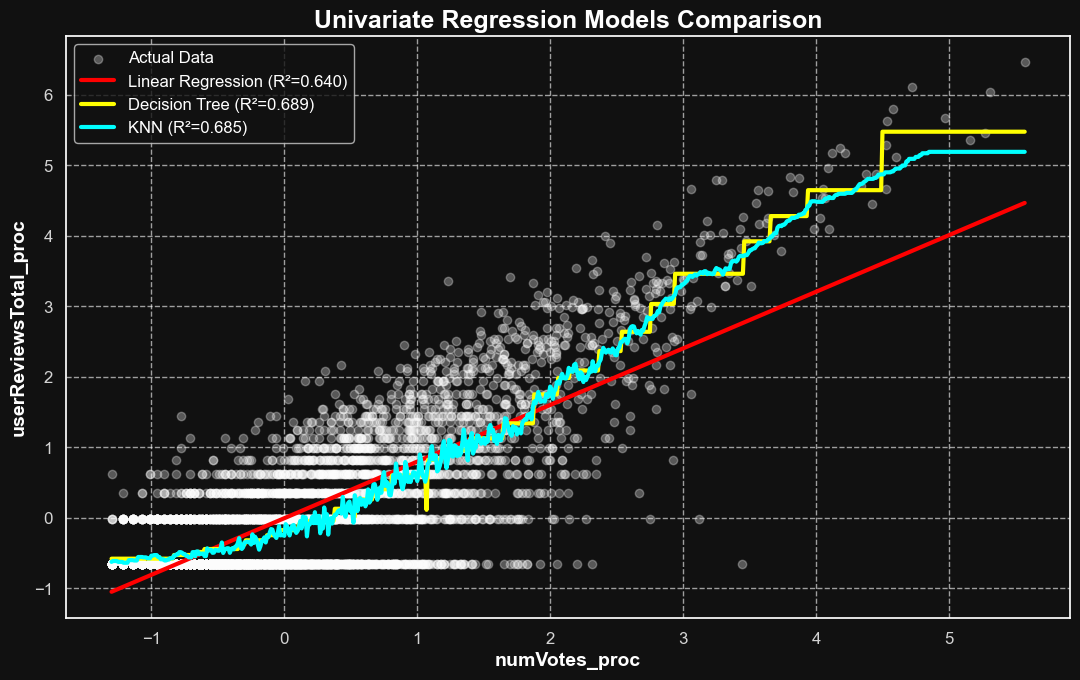

In [10]:
# --- 4.6. Comparative Visualization of Univariate Models (Corrected) ---

# Create a smooth range of X values for plotting the prediction lines
# We use .values.min() and .values.max() to extract the scalar min/max values
# from the pandas DataFrame, which is required by np.arange.
min_val = X_test_uni.values.min()
max_val = X_test_uni.values.max()
X_grid = np.arange(min_val, max_val, 0.01).reshape(-1, 1)

# Get predictions for all models on this smooth range
y_pred_linear_line = linear_regressor_uni.predict(X_grid)
y_pred_dt_line = best_dt_uni.predict(X_grid)
y_pred_knn_line = best_knn_uni.predict(X_grid)

# Plotting
plt.figure(figsize=(11, 7))

# Scatter plot of the actual test data
plt.scatter(X_test_uni, y_test, color='white', alpha=0.3, label='Actual Data')

# Plot the regression lines/curves
plt.plot(X_grid, y_pred_linear_line, color='red', linewidth=3, label=f'Linear Regression (R²={r2_uni:.3f})')
plt.plot(X_grid, y_pred_dt_line, color='yellow', linewidth=3, label=f'Decision Tree (R²={r2_dt_uni:.3f})')
plt.plot(X_grid, y_pred_knn_line, color='cyan', linewidth=3, label=f'KNN (R²={r2_knn_uni:.3f})')

plt.title('Univariate Regression Models Comparison', fontsize=18, weight='bold')
plt.xlabel(UNIVARIATE_PREDICTOR, fontsize=14, weight='bold')
plt.ylabel(TARGET_VARIABLE, fontsize=14, weight='bold')
plt.legend(prop={'size': 12})
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(f'{plots_dir}univariate_models_comparison.png', dpi=300)
plt.show()

### REGRESSIONE MULTIVARIATA

In [11]:
# --- 4.7. Data Preparation for Multivariate Regression ---

# --- Predictor Selection ---
# Based on the correlation analysis from the first chapter, we select the top 6
# most correlated numerical features to predict our target, 'userReviewsTotal_proc'.
# We will use their processed versions ('_proc') to ensure they are scaled and
# transformed appropriately for regression models.

MULTIVARIATE_PREDICTORS = [
    'numVotes_proc',
    'criticReviewsTotal_proc',
    'numRegions_proc',
    'awardNominationsExcludeWins_proc',
    'totalCredits_proc',
    'awardWins_proc'
]

# --- Create the DataFrames for the Multivariate Models ---
# The target variable 'y_train' and 'y_test' remains the same.
# We create new predictor DataFrames, 'X_train_multi' and 'X_test_multi'.

# Training set
X_train_multi = df_train[MULTIVARIATE_PREDICTORS]
# y_train is already defined and correct

# Test set
X_test_multi = df_test[MULTIVARIATE_PREDICTORS]
# y_test is already defined and correct

print("--- Data prepared for Multivariate Regression ---")
print(f"Number of selected predictors: {len(MULTIVARIATE_PREDICTORS)}")
print("Selected predictors (X):")
print(MULTIVARIATE_PREDICTORS)
print(f"\nTarget variable (Y): '{TARGET_VARIABLE}'")

print("\nShapes for the training set:")
print(f"X_train_multi shape: {X_train_multi.shape}")
print(f"y_train shape: {y_train.shape}")

--- Data prepared for Multivariate Regression ---
Number of selected predictors: 6
Selected predictors (X):
['numVotes_proc', 'criticReviewsTotal_proc', 'numRegions_proc', 'awardNominationsExcludeWins_proc', 'totalCredits_proc', 'awardWins_proc']

Target variable (Y): 'userReviewsTotal_proc'

Shapes for the training set:
X_train_multi shape: (15609, 6)
y_train shape: (15609,)


In [12]:
#### Regressione lineare Multivariata

In [13]:
# --- 4.8. Multivariate Linear Regression ---
print("--- Training Multivariate Linear Regression Model ---")

# 1. Instantiate the model
linear_regressor_multi = LinearRegression()

# 2. Train the model on the multivariate training data
linear_regressor_multi.fit(X_train_multi, y_train)

# 3. Make predictions on the test set
y_pred_multi_linear = linear_regressor_multi.predict(X_test_multi)

# 4. Evaluate the model's performance
mae_multi_linear = mean_absolute_error(y_test, y_pred_multi_linear)
rmse_multi_linear = np.sqrt(mean_squared_error(y_test, y_pred_multi_linear))
r2_multi_linear = r2_score(y_test, y_pred_multi_linear)

print("\n--- Multivariate Linear Regression Performance ---")
print(f"Mean Absolute Error (MAE): {mae_multi_linear:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_multi_linear:.4f}")
print(f"R-squared (R²): {r2_multi_linear:.4f}")

--- Training Multivariate Linear Regression Model ---

--- Multivariate Linear Regression Performance ---
Mean Absolute Error (MAE): 0.3883
Root Mean Squared Error (RMSE): 0.5247
R-squared (R²): 0.7231


In [14]:
#### Decision Tree Regressor (Regressione Multivariata)

In [15]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# --- Multivariate Decision Tree Regressor ---
print("--- Training Multivariate Decision Tree Regressor ---")

# 1. Define the parameter grid. We'll tune for depth and leaf size.
param_grid_dt_multi = {
    'max_depth': [3, 5, 7, 10, 12],
    'min_samples_leaf': [10, 20, 40, 60],
    'min_samples_split': [20, 40, 80]
}

# 2. Instantiate GridSearchCV, optimizing for R-squared
grid_search_dt_multi = GridSearchCV(DecisionTreeRegressor(random_state=42),
                                    param_grid=param_grid_dt_multi,
                                    cv=5,
                                    scoring='r2',
                                    n_jobs=-1)

# 3. Fit the model on the multivariate training data
grid_search_dt_multi.fit(X_train_multi, y_train)

# 4. Get the best model and its parameters
best_dt_multi = grid_search_dt_multi.best_estimator_
print("\nBest parameters found for Decision Tree:")
print(grid_search_dt_multi.best_params_)

# 5. Make predictions and evaluate
y_pred_multi_dt = best_dt_multi.predict(X_test_multi)

mae_multi_dt = mean_absolute_error(y_test, y_pred_multi_dt)
rmse_multi_dt = np.sqrt(mean_squared_error(y_test, y_pred_multi_dt))
r2_multi_dt = r2_score(y_test, y_pred_multi_dt)

print("\n--- Multivariate Decision Tree Performance ---")
print(f"Mean Absolute Error (MAE): {mae_multi_dt:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_multi_dt:.4f}")
print(f"R-squared (R²): {r2_multi_dt:.4f}")

--- Training Multivariate Decision Tree Regressor ---

Best parameters found for Decision Tree:
{'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 20}

--- Multivariate Decision Tree Performance ---
Mean Absolute Error (MAE): 0.3636
Root Mean Squared Error (RMSE): 0.5049
R-squared (R²): 0.7437


#### K-Neighbors Regressor (Regressione Multivariata)

In [16]:
from sklearn.neighbors import KNeighborsRegressor

# --- Multivariate K-Neighbors Regressor ---
print("\n--- Training Multivariate K-Neighbors Regressor ---")

# 1. Define the parameter grid.
param_grid_knn_multi = {
    'n_neighbors': [5, 11, 21, 31, 41, 51],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# 2. Instantiate GridSearchCV
grid_search_knn_multi = GridSearchCV(KNeighborsRegressor(n_jobs=-1),
                                     param_grid=param_grid_knn_multi,
                                     cv=5,
                                     scoring='r2',
                                     n_jobs=-1)

# 3. Fit the model
grid_search_knn_multi.fit(X_train_multi, y_train)

# 4. Get the best model and its parameters
best_knn_multi = grid_search_knn_multi.best_estimator_
print("\nBest parameters found for KNN:")
print(grid_search_knn_multi.best_params_)

# 5. Make predictions and evaluate
y_pred_multi_knn = best_knn_multi.predict(X_test_multi)

mae_multi_knn = mean_absolute_error(y_test, y_pred_multi_knn)
rmse_multi_knn = np.sqrt(mean_squared_error(y_test, y_pred_multi_knn))
r2_multi_knn = r2_score(y_test, y_pred_multi_knn)

print("\n--- Multivariate KNN Performance ---")
print(f"Mean Absolute Error (MAE): {mae_multi_knn:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_multi_knn:.4f}")
print(f"R-squared (R²): {r2_multi_knn:.4f}")


--- Training Multivariate K-Neighbors Regressor ---

Best parameters found for KNN:
{'metric': 'manhattan', 'n_neighbors': 31, 'weights': 'uniform'}

--- Multivariate KNN Performance ---
Mean Absolute Error (MAE): 0.3628
Root Mean Squared Error (RMSE): 0.5007
R-squared (R²): 0.7479


#### Visualizzazione Comparativa dei Modelli Multivariati

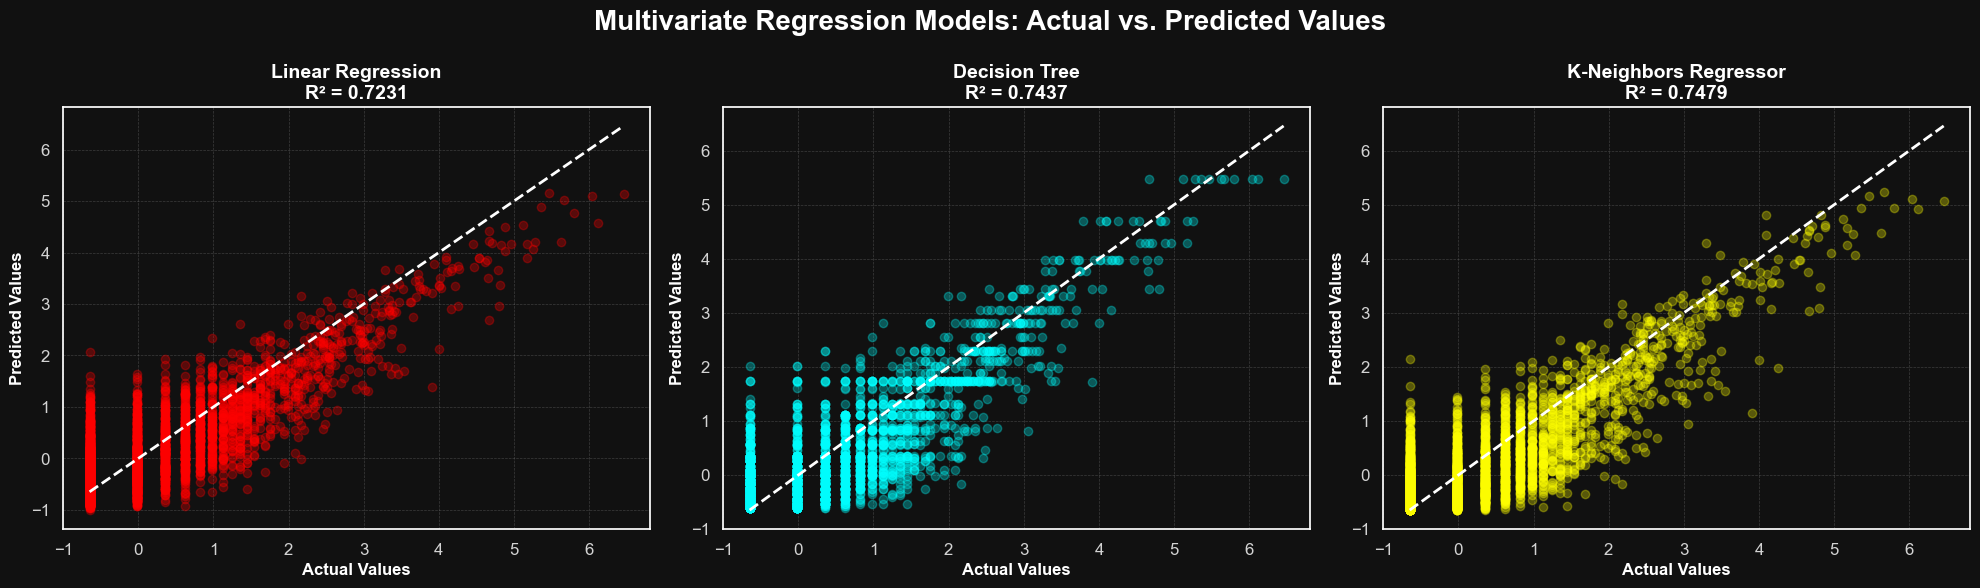

In [20]:
# --- 4.10. Comparative Visualization of Multivariate Models (Aesthetically Enhanced) ---
# For multivariate regression, the best way to visualize performance is to plot
# the actual values (y_test) against the predicted values (y_pred) for each model.
# A perfect model would have all points lying on a 45-degree diagonal line.

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Multivariate Regression Models: Actual vs. Predicted Values', fontsize=20, weight='bold')

# --- Styling Parameters ---
# Subtle grid style, as requested
grid_style = {'color': 'gray', 'linestyle': '--', 'linewidth': 0.5, 'alpha': 0.4}
# Powerful white reference line, as requested
line_style = {'color': 'white', 'linestyle': '--', 'lw': 2}


# --- Linear Regression Plot ---
axes[0].scatter(y_test, y_pred_multi_linear, alpha=0.3, color='red')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], **line_style)
axes[0].set_title(f'Linear Regression\nR² = {r2_multi_linear:.4f}', fontsize=14, weight='bold')
axes[0].set_xlabel('Actual Values', fontsize=12)
axes[0].set_ylabel('Predicted Values', fontsize=12)
axes[0].grid(**grid_style)

# --- Decision Tree Plot ---
axes[1].scatter(y_test, y_pred_multi_dt, alpha=0.3, color='cyan')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], **line_style)
axes[1].set_title(f'Decision Tree\nR² = {r2_multi_dt:.4f}', fontsize=14, weight='bold')
axes[1].set_xlabel('Actual Values', fontsize=12)
axes[1].set_ylabel('Predicted Values', fontsize=12)
axes[1].grid(**grid_style)

# --- KNN Plot ---
axes[2].scatter(y_test, y_pred_multi_knn, alpha=0.3, color='yellow')
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], **line_style)
axes[2].set_title(f'K-Neighbors Regressor\nR² = {r2_multi_knn:.4f}', fontsize=14, weight='bold')
axes[2].set_xlabel('Actual Values', fontsize=12)
axes[2].set_ylabel('Predicted Values', fontsize=12)
axes[2].grid(**grid_style)

plt.tight_layout()
plt.savefig(f'{plots_dir}multivariate_models_comparison_final.png', dpi=300, bbox_inches='tight')
plt.show()